# Experimento 2: versión anterior de la Etapa 3
Incluye tres cosas que se retiraron del notebook principal:
- **Embeddings de caracteres pre-entrenados** (derivados de GloVe 840B): congelados 38,29 %, ajustables 49,06 %, contra 49,51 % desde cero.
- **ReduceLROnPlateau** en R3 y R4: R4 llegó a 50,95 % ± 0,19 %.
- **Variantes de R3:** + Dropout 0,2 (49,06 %, dentro del desvío) y + embedding de 16 dim. (45,94 %).

# TP Final — Inteligencia Artificial 2026 (UNAB)
## Etapa 3: Embeddings de caracteres y modelo de lenguaje simple
### Predicción del siguiente carácter sobre *"The Festival"* (H. P. Lovecraft)
### Punto de partida
### Decisiones generales

# 0. Configuración y datos

In [1]:
# ==============================================================================
# 0.1 CONFIGURACIÓN DEL ENTORNO
# ==============================================================================
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import json
import time
import urllib.request
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)

SEED = 42
SEEDS = [42, 123, 456, 789, 2026]
np.random.seed(SEED)

print(f"TensorFlow {tf.__version__} | Keras {keras.__version__}")

TensorFlow 2.21.0 | Keras 3.15.1


In [2]:
# ==============================================================================
# 0.2 CARGA DEL TEXTO LIMPIO Y DE LA PARTICIÓN DE LA ETAPA 1
# ==============================================================================
BASE_DIR = Path.cwd().parent if (Path.cwd().parent / "data").exists() else Path.cwd()
PROC = BASE_DIR / "data" / "processed"

text = (PROC / "The_Festival_clean.txt").read_text(encoding="utf-8")
splits = json.load(open(PROC / "splits_bloques.json", encoding="utf-8"))

L = splits["L"]
limites = splits["limites_bloques"]
bloques_split = splits["bloques"]
vocabulary = list(splits["vocabulario"])
char2idx = {c: i for i, c in enumerate(vocabulary)}
idx2char = {i: c for c, i in char2idx.items()}
V = len(vocabulary)

def ventanas_de_bloques(ids):
    X, y = [], []
    for b in ids:
        ini, fin = limites[b]
        for i in range(ini, fin - L):
            X.append(text[i:i+L])
            y.append(text[i+L])
    return X, y

X_train, y_train = ventanas_de_bloques(bloques_split["train"])
X_dev,   y_dev   = ventanas_de_bloques(bloques_split["dev"])

# Entrada como índices enteros: (N, L)
a_indices = lambda X: np.array([[char2idx[c] for c in x] for x in X], dtype=np.int32)
Xi_train, Xi_dev = a_indices(X_train), a_indices(X_dev)
yi_train = np.array([char2idx[c] for c in y_train], dtype=np.int32)
yi_dev   = np.array([char2idx[c] for c in y_dev], dtype=np.int32)

print(f"|V| = {V} | L = {L}")
print(f"Train: {len(X_train):,} muestras | Dev: {len(X_dev):,} muestras")

|V| = 64 | L = 40
Train: 12,780 muestras | Dev: 2,880 muestras


In [3]:
# ==============================================================================
# 0.3 REFERENCIAS DE LAS ETAPAS 1 Y 2
# ==============================================================================
ref_base = json.load(open(PROC / "baseline_dev.json", encoding="utf-8"))
reg2 = json.load(open(PROC / "resultados_modelos.json", encoding="utf-8"))
ref2 = reg2["configuraciones"][reg2["ganador"]]

# Configuración de entrenamiento heredada del ganador de la Etapa 2
CFG2 = ref2["config"]
LR = CFG2["lr"]
DROPOUT = CFG2.get("dropout", 0.0)
EPOCAS = reg2["learning_rate"]["epocas"]
BATCH = 128
K = ref_base["K"]

print(f"Baseline (Etapa 1): {ref_base['accuracy_dev']*100:.2f}% en Dev")
print(f"Ganador Etapa 2 ({reg2['ganador']}): {ref2['dev_acc_mean']*100:.2f}% ± {ref2['dev_acc_std']*100:.2f}% en Dev")
print(f"Configuración heredada: lr = {LR:g} | Dropout = {DROPOUT} | {EPOCAS} épocas | batch {BATCH} | K = {K}")

Baseline (Etapa 1): 40.83% en Dev
Ganador Etapa 2 (Dropout 0.05): 48.71% ± 0.52% en Dev
Configuración heredada: lr = 0.0005 | Dropout = 0.05 | 100 épocas | batch 128 | K = 5


# 1. Embeddings pre-entrenados

In [4]:
# ==============================================================================
# 1.1 CARGA DE LOS VECTORES Y COBERTURA DEL VOCABULARIO
# ==============================================================================
URL_EMB = "https://raw.githubusercontent.com/minimaxir/char-embeddings/master/glove.840B.300d-char.txt"
RUTA_EMB = BASE_DIR / "data" / "external" / "glove.840B.300d-char.txt"
if not RUTA_EMB.exists():
    RUTA_EMB.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(URL_EMB, RUTA_EMB)

vectores = {}
for linea in RUTA_EMB.read_text(encoding="utf-8").splitlines():
    partes = linea.split(" ")
    vectores[partes[0]] = np.array(partes[1:], dtype=np.float32)
DIM_PRE = len(next(iter(vectores.values())))

# Matriz (|V|, 300) en el orden de char2idx
rng = np.random.default_rng(SEED)
escala = np.std(np.stack(list(vectores.values())))
E_pre = np.zeros((V, DIM_PRE), dtype=np.float32)
sin_vector = []
for c, i in char2idx.items():
    if c in vectores:
        E_pre[i] = vectores[c]
    else:
        E_pre[i] = rng.normal(0, escala, DIM_PRE)
        sin_vector.append(c)

frec = Counter(text)
vis = lambda c: {" ": "<SP>", "\n": "<NL>"}.get(c, c)
print(f"Vectores en el archivo: {len(vectores)} | dimensión: {DIM_PRE}")
print(f"Caracteres del vocabulario con vector: {V - len(sin_vector)} de {V}")
print(f"Sin vector: {[vis(c) for c in sin_vector]} -> {sum(frec[c] for c in sin_vector) / len(text) * 100:.1f}% del texto")

Vectores en el archivo: 94 | dimensión: 300
Caracteres del vocabulario con vector: 62 de 64
Sin vector: ['<SP>', '—'] -> 17.8% del texto


# 2. Consigna 4.3.B: Red densa sobre embeddings

In [5]:
# ==============================================================================
# 2.1 CONSTRUCCIÓN, ENTRENAMIENTO Y EVALUACIÓN CON 5 SEMILLAS
# ==============================================================================
def construir_modelo(tipo, k=K, emb_dim=16, emb_init=None, emb_trainable=True, dropout=DROPOUT, unidades_lstm=128):
    """
    tipo = "onehot": MLP de la Etapa 2 sobre one-hot aplanado.
    tipo = "densa":  Embedding -> Flatten -> MLP 128-64-32.
    tipo = "lstm":   Embedding -> LSTM -> Dropout -> softmax.
    """
    entrada = layers.Input(shape=(k,), dtype="int32")
    if tipo == "onehot":
        # One-hot exacto: embedding fijo con la matriz identidad
        x = layers.Embedding(V, V, embeddings_initializer=keras.initializers.Identity(), trainable=False)(entrada)
    else:
        init = keras.initializers.Constant(emb_init) if emb_init is not None else "uniform"
        x = layers.Embedding(V, emb_dim, embeddings_initializer=init, trainable=emb_trainable, name="embedding")(entrada)

    if tipo in ("onehot", "densa"):
        x = layers.Flatten()(x)
        for u in [128, 64, 32]:
            x = layers.Dense(u, activation="relu")(x)
            if dropout > 0:
                x = layers.Dropout(dropout)(x)
    else:
        x = layers.LSTM(unidades_lstm)(x)
        if dropout > 0:
            x = layers.Dropout(dropout)(x)

    salida = layers.Dense(V, activation="softmax")(x)
    return keras.Model(entrada, salida)

def evaluar(constructor, k, epochs=EPOCAS, seeds=SEEDS, lr=None, plateau=None, use_es=False, patience=5):
    """Entrena con cada semilla y devuelve (resumen, historial y modelo de la semilla 42)."""
    Xtr, Xdv = Xi_train[:, -k:], Xi_dev[:, -k:]
    corridas = []
    for s in seeds:
        keras.utils.set_random_seed(s)
        modelo = constructor()
        modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=lr or LR),
                       loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        cbs = []
        if plateau:
            cbs.append(callbacks.ReduceLROnPlateau(monitor="val_loss", **plateau))
        if use_es:
            cbs.append(callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True))
        t0 = time.perf_counter()
        h = modelo.fit(Xtr, yi_train, validation_data=(Xdv, yi_dev), epochs=epochs, batch_size=BATCH,
                       callbacks=cbs, verbose=0)
        t_run = time.perf_counter() - t0
        if s == SEED:
            h42, m42 = h.history, modelo
        loss_tr, acc_tr = [float(v) for v in modelo.evaluate(Xtr, yi_train, verbose=0)]
        loss_dv, acc_dv = [float(v) for v in modelo.evaluate(Xdv, yi_dev, verbose=0)]
        va = h.history["val_accuracy"]
        corridas.append({"seed": s, "tiempo": t_run, "train_acc": acc_tr, "dev_acc": acc_dv,
                         "brecha": acc_tr - acc_dv, "dev_loss": loss_dv, "dev_perp": float(np.exp(loss_dv)),
                         "pico_acc": float(max(va)), "ep_pico_acc": int(np.argmax(va)) + 1,
                         "epocas": len(h.history["loss"])})
    df_c = pd.DataFrame(corridas)
    resumen = {"params": int(sum(np.prod(w.shape) for w in m42.trainable_weights)), "k": k, "dev_acc_min": float(df_c["dev_acc"].min()), "corridas": corridas}
    for col in df_c.columns.drop("seed"):
        resumen[f"{col}_mean"] = float(df_c[col].mean())
        resumen[f"{col}_std"] = float(df_c[col].std())
    return resumen, h42, m42

MODELOS_DENSOS = {
    "E0 — One-hot (Etapa 2)":       lambda: construir_modelo("onehot"),
    "E1 — Desde cero, 16 dim.":     lambda: construir_modelo("densa", emb_dim=16),
    "E2 — Desde cero, 300 dim.":    lambda: construir_modelo("densa", emb_dim=DIM_PRE),
    "E3 — Pre-entrenado congelado": lambda: construir_modelo("densa", emb_dim=DIM_PRE, emb_init=E_pre, emb_trainable=False),
    "E4 — Pre-entrenado ajustable": lambda: construir_modelo("densa", emb_dim=DIM_PRE, emb_init=E_pre, emb_trainable=True),
}

resultados, historiales, modelos = {}, {}, {}
for nombre, constructor in MODELOS_DENSOS.items():
    resultados[nombre], historiales[nombre], modelos[nombre] = evaluar(constructor, k=K)
    r = resultados[nombre]
    print(f"  {nombre:<30} Dev: {r['dev_acc_mean']*100:.2f}% ± {r['dev_acc_std']*100:.2f}% | brecha {r['brecha_mean']*100:.2f} pp | {r['tiempo_mean']:.0f} s por corrida")

def tabla(nombres):
    filas = []
    for n in nombres:
        r = resultados[n]
        filas.append({"Modelo": n, "Parámetros entrenables": f"{r['params']:,}",
                      "Dev Acc (μ ± σ)": f"{r['dev_acc_mean']*100:.2f}% ± {r['dev_acc_std']*100:.2f}%",
                      "Peor semilla": f"{r['dev_acc_min']*100:.2f}%",
                      "Δ vs Etapa 2": f"{(r['dev_acc_mean'] - ref2['dev_acc_mean'])*100:+.2f} pp",
                      "Train Acc": f"{r['train_acc_mean']*100:.2f}%",
                      "Brecha": f"{r['brecha_mean']*100:.2f} pp",
                      "Dev Loss": f"{r['dev_loss_mean']:.4f}",
                      "Perplejidad": f"{r['dev_perp_mean']:.2f}",
                      "Pico Dev (época)": f"{r['pico_acc_mean']*100:.2f}% ({r['ep_pico_acc_mean']:.0f})",
                      "Épocas": f"{r['epocas_mean']:.0f}"})
    return pd.DataFrame(filas).set_index("Modelo")

display(tabla(MODELOS_DENSOS))

  E0 — One-hot (Etapa 2)         Dev: 48.71% ± 0.52% | brecha 20.72 pp | 92 s por corrida


  E1 — Desde cero, 16 dim.       Dev: 47.88% ± 0.73% | brecha 10.11 pp | 37 s por corrida


  E2 — Desde cero, 300 dim.      Dev: 49.51% ± 0.81% | brecha 25.62 pp | 61 s por corrida


  E3 — Pre-entrenado congelado   Dev: 38.29% ± 0.80% | brecha 0.35 pp | 60 s por corrida


  E4 — Pre-entrenado ajustable   Dev: 49.06% ± 0.75% | brecha 20.83 pp | 62 s por corrida


,Parámetros entrenables,Dev Acc (μ ± σ),Peor semilla,Δ vs Etapa 2,Train Acc,Brecha,Dev Loss,Perplejidad,Pico Dev (época),Épocas
Modelo,,,,,,,,,,
E0 — One-hot (Etapa 2),"53,536",48.71% ± 0.52%,48.16%,+0.00 pp,69.43%,20.72 pp,2.0363,7.66,49.26% (88),100
"E1 — Desde cero, 16 dim.","23,840",47.88% ± 0.73%,47.05%,-0.83 pp,57.99%,10.11 pp,1.8739,6.51,48.21% (95),100
"E2 — Desde cero, 300 dim.","223,776",49.51% ± 0.81%,48.58%,+0.81 pp,75.13%,25.62 pp,2.1590,8.66,50.05% (76),100
E3 — Pre-entrenado congelado,"204,576",38.29% ± 0.80%,37.22%,-10.42 pp,38.64%,0.35 pp,2.1206,8.34,38.74% (97),100
E4 — Pre-entrenado ajustable,"223,776",49.06% ± 0.75%,48.33%,+0.35 pp,69.88%,20.83 pp,2.0382,7.68,49.50% (90),100


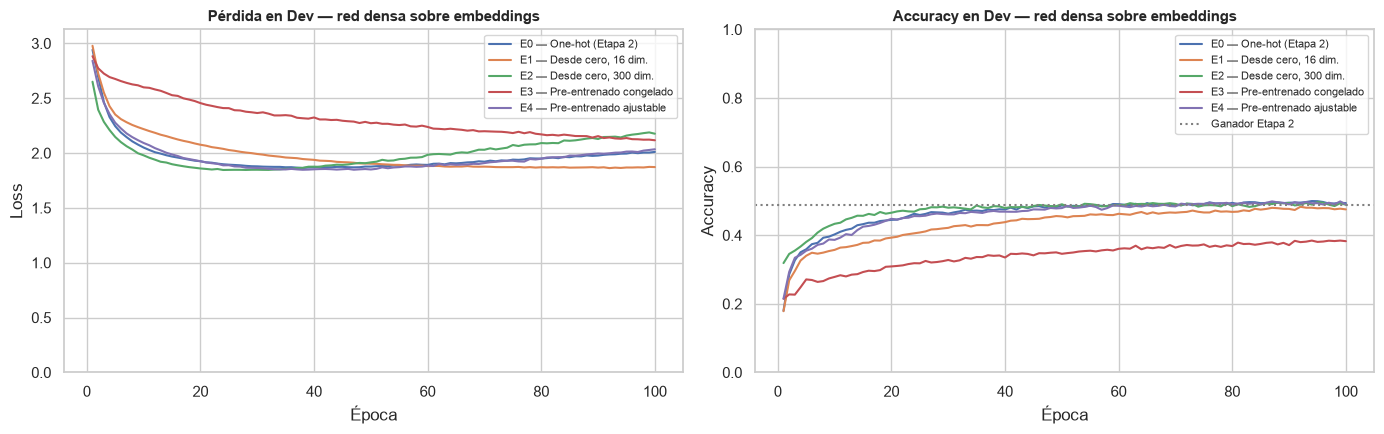

In [6]:
# ==============================================================================
# 2.2 CURVAS DE VALIDACIÓN (semilla 42)
# ==============================================================================
def graficar_curvas(nombres, titulo):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for n in nombres:
        h = historiales[n]
        ep = range(1, len(h["loss"]) + 1)
        axes[0].plot(ep, h["val_loss"], label=n)
        axes[1].plot(ep, h["val_accuracy"], label=n)
    axes[1].axhline(ref2["dev_acc_mean"], color="gray", linestyle=":", label="Ganador Etapa 2")
    axes[0].set_ylim(0, max(max(historiales[n]["val_loss"]) for n in nombres) * 1.05)
    axes[1].set_ylim(0, 1)
    axes[0].set_title(f"Pérdida en Dev — {titulo}", fontsize=11, fontweight="bold")
    axes[1].set_title(f"Accuracy en Dev — {titulo}", fontsize=11, fontweight="bold")
    axes[0].set_ylabel("Loss")
    axes[1].set_ylabel("Accuracy")
    for ax in axes:
        ax.set_xlabel("Época")
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

graficar_curvas(MODELOS_DENSOS, "red densa sobre embeddings")

# 3. Modelo de lenguaje simple: LSTM

Representación elegida para la LSTM: E2 — Desde cero, 300 dim.



  R1 — LSTM, 5 caracteres    Dev: 49.69% ± 0.12% | brecha 28.67 pp | 133 s por corrida


  R2 — LSTM, 40 caracteres   Dev: 45.06% ± 1.70% | brecha 27.41 pp | 863 s por corrida


,Parámetros entrenables,Dev Acc (μ ± σ),Peor semilla,Δ vs Etapa 2,Train Acc,Brecha,Dev Loss,Perplejidad,Pico Dev (época),Épocas
Modelo,,,,,,,,,,
E0 — One-hot (Etapa 2),"53,536",48.71% ± 0.52%,48.16%,+0.00 pp,69.43%,20.72 pp,2.0363,7.66,49.26% (88),100
"E2 — Desde cero, 300 dim.","223,776",49.51% ± 0.81%,48.58%,+0.81 pp,75.13%,25.62 pp,2.1590,8.66,50.05% (76),100
"R1 — LSTM, 5 caracteres","247,104",49.69% ± 0.12%,49.51%,+0.98 pp,78.36%,28.67 pp,2.0335,7.64,50.81% (61),100
"R2 — LSTM, 40 caracteres","247,104",45.06% ± 1.70%,43.06%,-3.65 pp,72.48%,27.41 pp,2.1420,8.54,48.32% (51),100


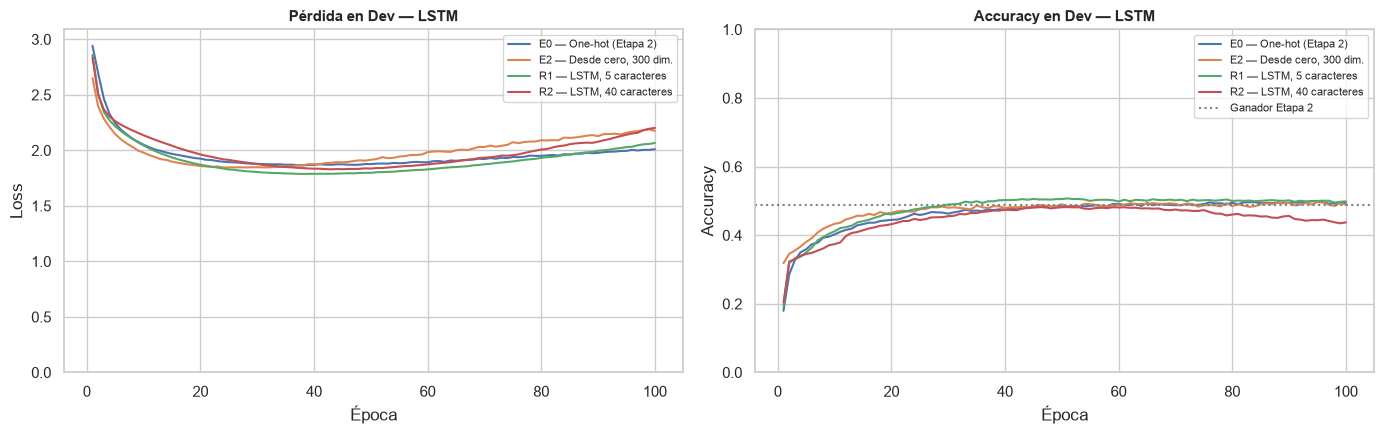

In [7]:
# ==============================================================================
# 3.1 LSTM CON LA MEJOR REPRESENTACIÓN DE LA SECCIÓN 2
# ==============================================================================
candidatos_emb = [n for n in MODELOS_DENSOS if not n.startswith("E0")]
MEJOR_EMB = max(candidatos_emb, key=lambda n: resultados[n]["dev_acc_mean"])
cfg_emb = {
    "E1 — Desde cero, 16 dim.":     dict(emb_dim=16),
    "E2 — Desde cero, 300 dim.":    dict(emb_dim=DIM_PRE),
    "E3 — Pre-entrenado congelado": dict(emb_dim=DIM_PRE, emb_init=E_pre, emb_trainable=False),
    "E4 — Pre-entrenado ajustable": dict(emb_dim=DIM_PRE, emb_init=E_pre, emb_trainable=True),
}[MEJOR_EMB]
print(f"Representación elegida para la LSTM: {MEJOR_EMB}\n")

MODELOS_LSTM = {
    "R1 — LSTM, 5 caracteres":  (lambda: construir_modelo("lstm", k=K, **cfg_emb), K),
    "R2 — LSTM, 40 caracteres": (lambda: construir_modelo("lstm", k=L, **cfg_emb), L),
}
for nombre, (constructor, k) in MODELOS_LSTM.items():
    resultados[nombre], historiales[nombre], modelos[nombre] = evaluar(constructor, k=k)
    r = resultados[nombre]
    print(f"  {nombre:<26} Dev: {r['dev_acc_mean']*100:.2f}% ± {r['dev_acc_std']*100:.2f}% | brecha {r['brecha_mean']*100:.2f} pp | {r['tiempo_mean']:.0f} s por corrida")

display(tabla(["E0 — One-hot (Etapa 2)", MEJOR_EMB] + list(MODELOS_LSTM)))
graficar_curvas(["E0 — One-hot (Etapa 2)", MEJOR_EMB] + list(MODELOS_LSTM), "LSTM")

### 3.2 Regularización de la LSTM de 40 caracteres

  R3 — LSTM 40 + Plateau + ES                          Dev: 48.81% ± 0.63% | brecha 10.74 pp | 45 épocas | 5695 s por corrida


  R3 — LSTM 40 + Plateau + ES + Dropout 0,2            Dev: 49.06% ± 0.48% | brecha 10.37 pp | 42 épocas | 266 s por corrida


  R3 — LSTM 40 + Plateau + ES + Embedding 16 dim.      Dev: 45.94% ± 0.59% | brecha 7.03 pp | 56 épocas | 300 s por corrida

Mejor LSTM de 40 caracteres: R3 — LSTM 40 + Plateau + ES


Modelo actual  \
Paso Candidato                                                                      
1    R3 — LSTM 40 + Plateau + ES + Dropout 0,2        R3 — LSTM 40 + Plateau + ES   
     R3 — LSTM 40 + Plateau + ES + Embedding 16 dim.  R3 — LSTM 40 + Plateau + ES   

                                                              Se agrega  \
Paso Candidato                                                            
1    R3 — LSTM 40 + Plateau + ES + Dropout 0,2              Dropout 0,2   
     R3 — LSTM 40 + Plateau + ES + Embedding 16 dim.  Embedding 16 dim.   

                                                     Dev Acc (μ ± σ)  \
Paso Candidato                                                         
1    R3 — LSTM 40 + Plateau + ES + Dropout 0,2        49.06% ± 0.48%   
     R3 — LSTM 40 + Plateau + ES + Embedding 16 dim.  45.94% ± 0.59%   

                                                      Ganancia   Umbral  \
Paso Candidato                                                            
1    R3 — LSTM 40 + Plateau + ES + Dropout 0,2        +0.25 pp  0.63 pp   
     R3 — LSTM 40 + Plateau + ES + Embedding 16 dim.  -2.87 pp  0.63 pp   

                                                     ¿Se acepta?  
Paso Candidato                                                    
1    R3 — LSTM 40 + Plateau + ES + Dropout 0,2                No  
     R3 — LSTM 40 + Plateau + ES + Embedding 16 dim.          No

,Parámetros entrenables,Dev Acc (μ ± σ),Peor semilla,Δ vs Etapa 2,Train Acc,Brecha,Dev Loss,Perplejidad,Pico Dev (época),Épocas
Modelo,,,,,,,,,,
"R1 — LSTM, 5 caracteres","247,104",49.69% ± 0.12%,49.51%,+0.98 pp,78.36%,28.67 pp,2.0335,7.64,50.81% (61),100
"R2 — LSTM, 40 caracteres","247,104",45.06% ± 1.70%,43.06%,-3.65 pp,72.48%,27.41 pp,2.1420,8.54,48.32% (51),100
R3 — LSTM 40 + Plateau + ES,"247,104",48.81% ± 0.63%,47.95%,+0.10 pp,59.55%,10.74 pp,1.7940,6.01,48.92% (38),45
"R3 — LSTM 40 + Plateau + ES + Dropout 0,2","247,104",49.06% ± 0.48%,48.30%,+0.35 pp,59.43%,10.37 pp,1.7840,5.95,49.20% (37),42
R3 — LSTM 40 + Plateau + ES + Embedding 16 dim.,"83,520",45.94% ± 0.59%,45.14%,-2.77 pp,52.97%,7.03 pp,1.8899,6.62,46.20% (53),56


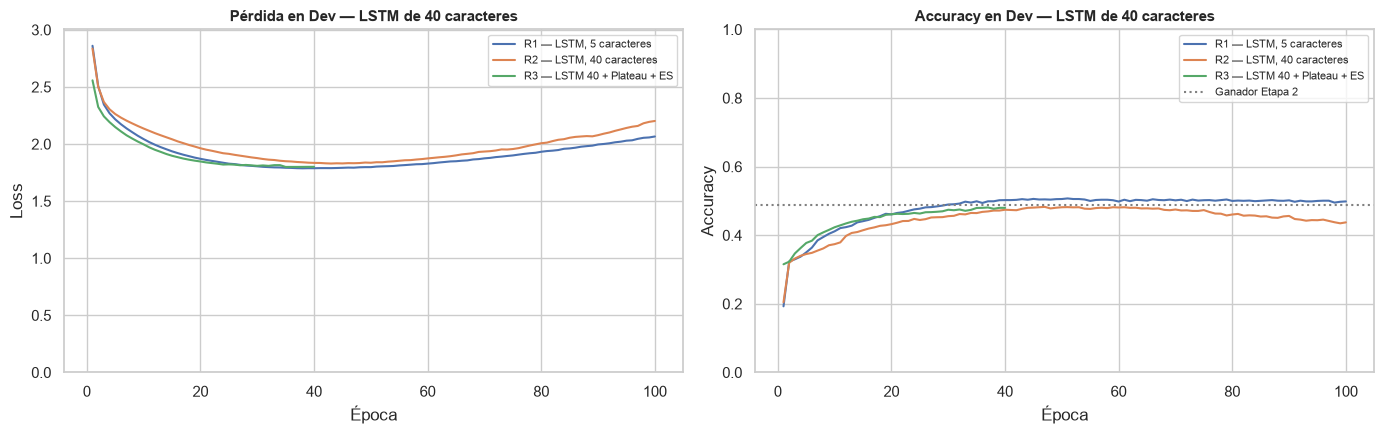

In [8]:
# ==============================================================================
# 3.2 REGULARIZACIÓN INCREMENTAL DE LA LSTM DE 40 CARACTERES (5 semillas)
# ==============================================================================
PLATEAU = {"factor": 0.2, "patience": 2, "min_lr": 1e-6}  # "Plateau agresivo" de la Etapa 2 (sección 7.3)
LR_PLATEAU = 1e-3

def lstm40(emb, dropout):
    return lambda: construir_modelo("lstm", k=L, dropout=dropout, **emb)

def evaluar_lstm40(nombre, emb, dropout):
    if nombre not in resultados:
        resultados[nombre], historiales[nombre], modelos[nombre] = evaluar(
            lstm40(emb, dropout), k=L, lr=LR_PLATEAU, plateau=PLATEAU, use_es=True, patience=5)
        resultados[nombre]["config_lstm"] = {"emb": {k: v for k, v in emb.items() if k != "emb_init"},
                                             "dropout": dropout, "lr": LR_PLATEAU, "plateau": PLATEAU, "es_patience": 5}
    r = resultados[nombre]
    print(f"  {nombre:<52} Dev: {r['dev_acc_mean']*100:.2f}% ± {r['dev_acc_std']*100:.2f}% | "
          f"brecha {r['brecha_mean']*100:.2f} pp | {r['epocas_mean']:.0f} épocas | {r['tiempo_mean']:.0f} s por corrida")
    return nombre

# Paso 1: Early Stopping + ReduceLROnPlateau
actual = evaluar_lstm40("R3 — LSTM 40 + Plateau + ES", cfg_emb, DROPOUT)
actual_args = {"emb": cfg_emb, "dropout": DROPOUT}

# Paso 2 en adelante: combinación incremental
CANDIDATOS_LSTM = {
    "Dropout 0,2": {"dropout": 0.2},
    "Embedding 16 dim.": {"emb": {"emb_dim": 16}},
}
pasos_lstm = []
restantes = list(CANDIDATOS_LSTM)
paso = 1
while restantes:
    candidatos = []
    for t in restantes:
        args = {**actual_args, **CANDIDATOS_LSTM[t]}
        candidatos.append((t, args, evaluar_lstm40(f"{actual} + {t}", **args)))
    t_mejor, args_mejor, n_mejor = max(candidatos, key=lambda c: resultados[c[2]]["dev_acc_mean"])
    umbral = resultados[actual]["dev_acc_std"]
    ganancia = resultados[n_mejor]["dev_acc_mean"] - resultados[actual]["dev_acc_mean"]
    for t, args, n in candidatos:
        g = resultados[n]["dev_acc_mean"] - resultados[actual]["dev_acc_mean"]
        pasos_lstm.append({"Paso": paso, "Modelo actual": actual, "Se agrega": t, "Candidato": n,
                           "Dev Acc (μ ± σ)": f"{resultados[n]['dev_acc_mean']*100:.2f}% ± {resultados[n]['dev_acc_std']*100:.2f}%",
                           "Ganancia": f"{g*100:+.2f} pp", "Umbral": f"{umbral*100:.2f} pp",
                           "¿Se acepta?": "Sí" if (n == n_mejor and ganancia > umbral) else "No"})
    if ganancia <= umbral:
        break
    actual, actual_args = n_mejor, args_mejor
    restantes.remove(t_mejor)
    paso += 1

MEJOR_LSTM40 = actual
print(f"\nMejor LSTM de 40 caracteres: {MEJOR_LSTM40}")
display(pd.DataFrame(pasos_lstm).set_index(["Paso", "Candidato"]))

modelos_lstm40 = list(dict.fromkeys(["R2 — LSTM, 40 caracteres", "R3 — LSTM 40 + Plateau + ES"] + [p["Candidato"] for p in pasos_lstm]))
display(tabla(["R1 — LSTM, 5 caracteres"] + modelos_lstm40))
# dict.fromkeys evita repetir R3 en la leyenda cuando es también el mejor modelo
graficar_curvas(list(dict.fromkeys(["R1 — LSTM, 5 caracteres", "R2 — LSTM, 40 caracteres", "R3 — LSTM 40 + Plateau + ES", MEJOR_LSTM40])), "LSTM de 40 caracteres")

### 3.3 Control: la LSTM de 5 caracteres con el mismo esquema

  R4 — LSTM 5 + Plateau + ES     Dev: 50.95% ± 0.19% | brecha 12.48 pp | 33 épocas | 43 s por corrida
  Ganancia sobre R1: +1.26 pp (desvío de R1: 0.12 pp)
  Diferencia con R3 (40 caracteres, mismo esquema): +2.15 pp


,Parámetros entrenables,Dev Acc (μ ± σ),Peor semilla,Δ vs Etapa 2,Train Acc,Brecha,Dev Loss,Perplejidad,Pico Dev (época),Épocas
Modelo,,,,,,,,,,
"R1 — LSTM, 5 caracteres","247,104",49.69% ± 0.12%,49.51%,+0.98 pp,78.36%,28.67 pp,2.0335,7.64,50.81% (61),100
R4 — LSTM 5 + Plateau + ES,"247,104",50.95% ± 0.19%,50.73%,+2.24 pp,63.43%,12.48 pp,1.7627,5.83,51.08% (29),33
R3 — LSTM 40 + Plateau + ES,"247,104",48.81% ± 0.63%,47.95%,+0.10 pp,59.55%,10.74 pp,1.7940,6.01,48.92% (38),45


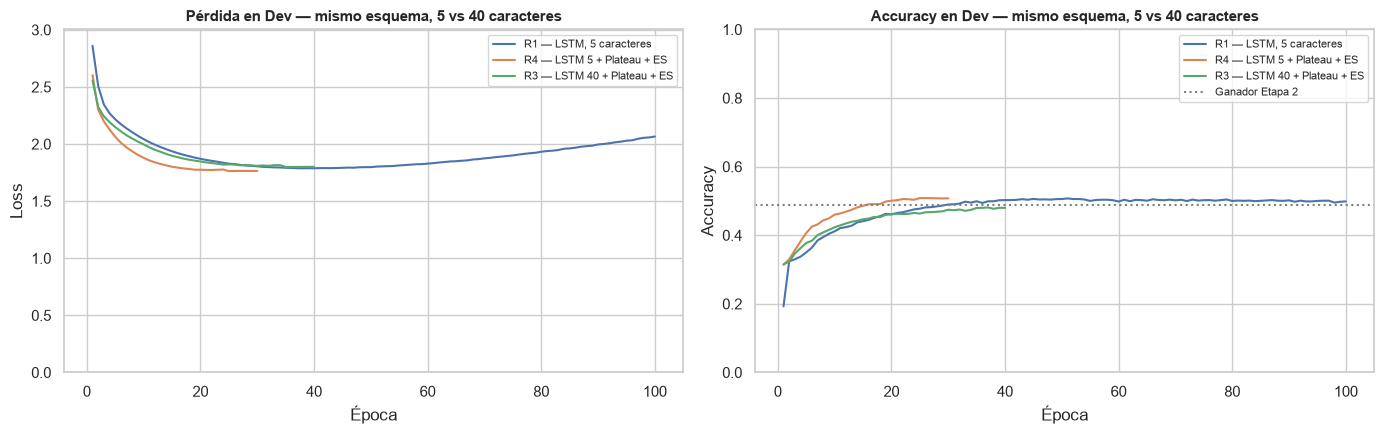

In [9]:
# ==============================================================================
# 3.3 CONTROL: LSTM DE 5 CARACTERES CON EL ESQUEMA DE R3 (5 semillas)
# ==============================================================================
R4 = "R4 — LSTM 5 + Plateau + ES"
if R4 not in resultados:
    resultados[R4], historiales[R4], modelos[R4] = evaluar(
        lambda: construir_modelo("lstm", k=K, **cfg_emb), k=K, lr=LR_PLATEAU, plateau=PLATEAU, use_es=True, patience=5)
    resultados[R4]["config_lstm"] = {"emb": {k: v for k, v in cfg_emb.items() if k != "emb_init"},
                                     "dropout": DROPOUT, "lr": LR_PLATEAU, "plateau": PLATEAU, "es_patience": 5}
r = resultados[R4]
print(f"  {R4:<30} Dev: {r['dev_acc_mean']*100:.2f}% ± {r['dev_acc_std']*100:.2f}% | "
      f"brecha {r['brecha_mean']*100:.2f} pp | {r['epocas_mean']:.0f} épocas | {r['tiempo_mean']:.0f} s por corrida")
print(f"  Ganancia sobre R1: {(r['dev_acc_mean'] - resultados['R1 — LSTM, 5 caracteres']['dev_acc_mean'])*100:+.2f} pp "
      f"(desvío de R1: {resultados['R1 — LSTM, 5 caracteres']['dev_acc_std']*100:.2f} pp)")
print(f"  Diferencia con R3 (40 caracteres, mismo esquema): {(r['dev_acc_mean'] - resultados['R3 — LSTM 40 + Plateau + ES']['dev_acc_mean'])*100:+.2f} pp")

comparadas_33 = list(dict.fromkeys(["R1 — LSTM, 5 caracteres", R4, "R3 — LSTM 40 + Plateau + ES", MEJOR_LSTM40]))
display(tabla(comparadas_33))
graficar_curvas(comparadas_33, "mismo esquema, 5 vs 40 caracteres")

# 4. Comparación con la Etapa 2

In [10]:
# ==============================================================================
# 4.1 TABLA FINAL Y MEJORA SOBRE LA ETAPA 2
# ==============================================================================
GANADOR3 = max(resultados, key=lambda n: resultados[n]["dev_acc_mean"])
r3 = resultados[GANADOR3]

print(f"Ganador de la Etapa 3: {GANADOR3}")
print(f"  • Dev: {r3['dev_acc_mean']*100:.2f}% ± {r3['dev_acc_std']*100:.2f}% (peor semilla {r3['dev_acc_min']*100:.2f}%)")
print(f"  • Mejora sobre el ganador de la Etapa 2 ({ref2['dev_acc_mean']*100:.2f}%): {(r3['dev_acc_mean'] - ref2['dev_acc_mean'])*100:+.2f} pp")
print(f"  • Mejora sobre el baseline ({ref_base['accuracy_dev']*100:.2f}%): {(r3['dev_acc_mean'] - ref_base['accuracy_dev'])*100:+.2f} pp\n")
display(tabla(list(resultados)))

with open(PROC / "resultados_etapa3.json", "w", encoding="utf-8") as f:
    json.dump({"config": {"lr": LR, "dropout": DROPOUT, "plateau_lstm40": PLATEAU, "lr_lstm40": LR_PLATEAU, "epocas": EPOCAS, "batch": BATCH, "K": K, "L": L},
               "embeddings_pre": {"fuente": URL_EMB, "dim": DIM_PRE, "sin_vector": sin_vector},
               "referencia_etapa2": {"modelo": reg2["ganador"], "dev_acc_mean": ref2["dev_acc_mean"]},
               "resultados": resultados, "mejor_embedding": MEJOR_EMB, "pasos_lstm40": pasos_lstm,
               "mejor_lstm40": MEJOR_LSTM40, "ganador": GANADOR3},
              f, indent=2, ensure_ascii=False, default=float)
print("Resultados guardados en data/processed/resultados_etapa3.json")

Ganador de la Etapa 3: R4 — LSTM 5 + Plateau + ES
  • Dev: 50.95% ± 0.19% (peor semilla 50.73%)
  • Mejora sobre el ganador de la Etapa 2 (48.71%): +2.24 pp
  • Mejora sobre el baseline (40.83%): +10.12 pp



,Parámetros entrenables,Dev Acc (μ ± σ),Peor semilla,Δ vs Etapa 2,Train Acc,Brecha,Dev Loss,Perplejidad,Pico Dev (época),Épocas
Modelo,,,,,,,,,,
E0 — One-hot (Etapa 2),"53,536",48.71% ± 0.52%,48.16%,+0.00 pp,69.43%,20.72 pp,2.0363,7.66,49.26% (88),100
"E1 — Desde cero, 16 dim.","23,840",47.88% ± 0.73%,47.05%,-0.83 pp,57.99%,10.11 pp,1.8739,6.51,48.21% (95),100
"E2 — Desde cero, 300 dim.","223,776",49.51% ± 0.81%,48.58%,+0.81 pp,75.13%,25.62 pp,2.1590,8.66,50.05% (76),100
E3 — Pre-entrenado congelado,"204,576",38.29% ± 0.80%,37.22%,-10.42 pp,38.64%,0.35 pp,2.1206,8.34,38.74% (97),100
E4 — Pre-entrenado ajustable,"223,776",49.06% ± 0.75%,48.33%,+0.35 pp,69.88%,20.83 pp,2.0382,7.68,49.50% (90),100
"R1 — LSTM, 5 caracteres","247,104",49.69% ± 0.12%,49.51%,+0.98 pp,78.36%,28.67 pp,2.0335,7.64,50.81% (61),100
"R2 — LSTM, 40 caracteres","247,104",45.06% ± 1.70%,43.06%,-3.65 pp,72.48%,27.41 pp,2.1420,8.54,48.32% (51),100
R3 — LSTM 40 + Plateau + ES,"247,104",48.81% ± 0.63%,47.95%,+0.10 pp,59.55%,10.74 pp,1.7940,6.01,48.92% (38),45
"R3 — LSTM 40 + Plateau + ES + Dropout 0,2","247,104",49.06% ± 0.48%,48.30%,+0.35 pp,59.43%,10.37 pp,1.7840,5.95,49.20% (37),42


Resultados guardados en data/processed/resultados_etapa3.json


# 5. Consigna 4.3.B: Qué ejemplos siguen siendo difíciles

,Casos en Dev,E0 — One-hot (Etapa 2),R4 — LSTM 5 + Plateau + ES,Δ (pp)
espacio,514,0.8930,0.9125,1.9455
vocal,817,0.4223,0.4308,0.8568
consonante,1451,0.4197,0.4369,1.7229
mayúscula,38,0.1579,0.1842,2.6316
puntuación/dígito,60,0.0500,0.0333,-1.6667


,Casos en Dev,E0 — One-hot (Etapa 2),R4 — LSTM 5 + Plateau + ES,Δ (pp)
0,511,0.1859,0.2035,1.7613
1,513,0.4834,0.5107,2.7290
2,487,0.5380,0.5359,-0.2053
3,429,0.6247,0.6434,1.8648
4,294,0.5748,0.5782,0.3401
5+,646,0.5882,0.6053,1.7028


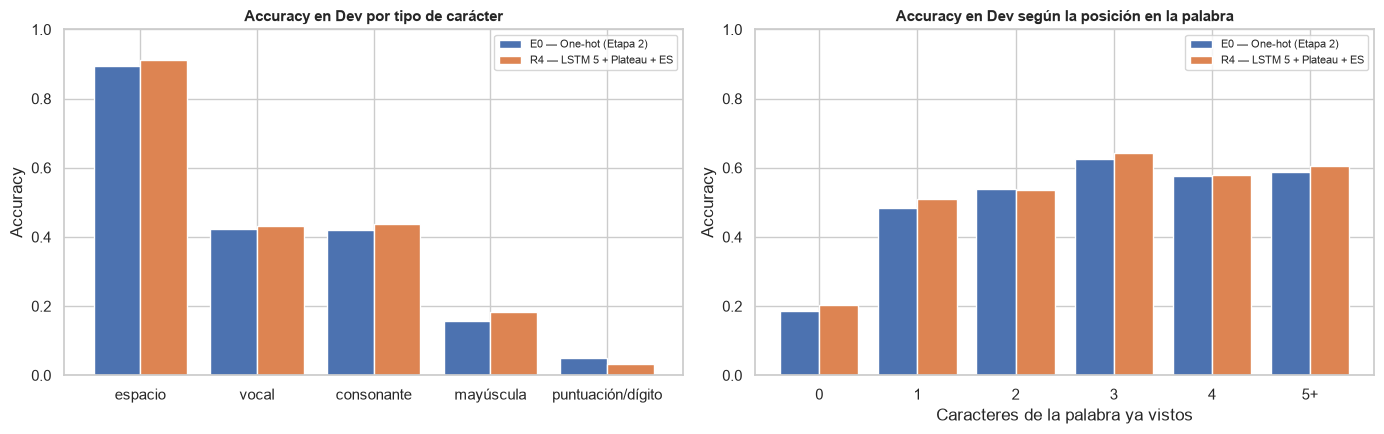

In [11]:
# ==============================================================================
# 5.1 ACCURACY POR TIPO DE CARÁCTER Y POR POSICIÓN EN LA PALABRA
# ==============================================================================
TIPOS_CHAR = ["espacio", "vocal", "consonante", "mayúscula", "puntuación/dígito"]

def tipo_caracter(c):
    if c == " ":
        return "espacio"
    if c.isupper():
        return "mayúscula"
    if c in "aeiou":
        return "vocal"
    if c.isalpha():
        return "consonante"
    return "puntuación/dígito"

def posicion_en_palabra(ctx):
    """Caracteres de la palabra actual ya vistos (0 = el contexto termina en espacio)."""
    p = len(ctx) - 1 - ctx.rfind(" ")
    return str(p) if p < 5 else "5+"

def proba(nombre):
    k = resultados[nombre]["k"]
    return modelos[nombre].predict(Xi_dev[:, -k:], verbose=0)

tipos_dev = np.array([tipo_caracter(c) for c in y_dev])
pos_dev = np.array([posicion_en_palabra(x) for x in X_dev])
POSICIONES = ["0", "1", "2", "3", "4", "5+"]

comparados = list(dict.fromkeys(["E0 — One-hot (Etapa 2)", GANADOR3]))
aciertos = {n: proba(n).argmax(axis=1) == yi_dev for n in comparados}

def acc_por_grupo(grupos, orden):
    df = pd.DataFrame({"Casos en Dev": pd.Series(grupos).value_counts().reindex(orden)})
    for n in comparados:
        df[n] = [aciertos[n][grupos == g].mean() for g in orden]
    if len(comparados) == 2:
        df["Δ (pp)"] = (df[comparados[1]] - df[comparados[0]]) * 100
    return df

df_tipo = acc_por_grupo(tipos_dev, TIPOS_CHAR)
df_pos = acc_por_grupo(pos_dev, POSICIONES)
display(df_tipo.round(4))
display(df_pos.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
df_tipo[comparados].plot.bar(ax=axes[0], rot=0, width=0.8)
df_pos[comparados].plot.bar(ax=axes[1], rot=0, width=0.8)
axes[0].set_title("Accuracy en Dev por tipo de carácter", fontsize=11, fontweight="bold")
axes[1].set_title("Accuracy en Dev según la posición en la palabra", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Caracteres de la palabra ya vistos")
for ax in axes:
    ax.set_ylim(0, 1)
    ax.set_ylabel("Accuracy")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [12]:
# ==============================================================================
# 5.2 DIEZ ERRORES CONCRETOS DEL GANADOR (dos por tipo de carácter)
# ==============================================================================
P_gan = proba(GANADOR3)
pred_gan = P_gan.argmax(axis=1)
errores = np.where(pred_gan != yi_dev)[0]
rng_ej = np.random.default_rng(SEED)

filas_ej = []
for t in TIPOS_CHAR:
    idx_t = errores[tipos_dev[errores] == t]
    for i in rng_ej.choice(idx_t, size=min(2, len(idx_t)), replace=False):
        orden = np.argsort(P_gan[i])[::-1]
        filas_ej.append({
            "Tipo real": t,
            "Contexto (últimos 30)": "..." + X_dev[i][-30:],
            "Real": vis(y_dev[i]),
            "Predicho": vis(idx2char[pred_gan[i]]),
            "Puesto del real": int(np.where(orden == yi_dev[i])[0][0]) + 1,
            "P(real)": round(float(P_gan[i, yi_dev[i]]), 3),
            "Top-5": " | ".join(f"{vis(idx2char[j])} {P_gan[i, j]:.2f}" for j in orden[:5]),
        })

pd.set_option("display.max_colwidth", 60)
display(pd.DataFrame(filas_ej))
print(f"Errores del ganador en Dev: {len(errores)} de {len(yi_dev)} ({len(errores)/len(yi_dev)*100:.2f}%)")

,Tipo real,Contexto (últimos 30),Real,Predicho,Puesto del real,P(real),Top-5
0,espacio,...isting willows writhed against,<SP>,o,2,0.199,"o 0.24 | <SP> 0.20 | e 0.11 | , 0.10 | u 0.07"
1,espacio,...e blasphemous book in my hands,<SP>,",",2,0.271,", 0.51 | <SP> 0.27 | i 0.05 | . 0.04 | s 0.04"
2,vocal,...nd though he made signs that h,e,a,3,0.168,a 0.48 | i 0.19 | e 0.17 | o 0.14 | u 0.01
3,vocal,...sured me; and though he made s,i,e,8,0.037,e 0.35 | t 0.14 | a 0.11 | o 0.09 | c 0.05
4,consonante,...nd the blasphemous book in my,h,s,8,0.036,s 0.25 | t 0.21 | o 0.07 | p 0.06 | a 0.05
5,consonante,...hers had called me to the old,t,m,5,0.057,m 0.34 | s 0.10 | a 0.08 | w 0.07 | t 0.06
6,mayúscula,...d the first stars of evening.,A,T,3,0.079,T 0.33 | I 0.19 | A 0.08 | W 0.08 | B 0.04
7,mayúscula,"...seemed to be occupied, though",I,t,8,0.026,t 0.49 | s 0.10 | w 0.07 | i 0.06 | h 0.05
8,puntuación/dígito,...sed in a loose antique costume,",",<SP>,6,0.051,<SP> 0.35 | s 0.15 | d 0.15 | l 0.13 | . 0.06
9,puntuación/dígito,... was certainly nervous waiting,",",<SP>,2,0.041,"<SP> 0.92 | , 0.04 | s 0.02 | ; 0.01 | - 0.00"


Errores del ganador en Dev: 1416 de 2880 (49.17%)


# 6. Qué aprendieron los embeddings

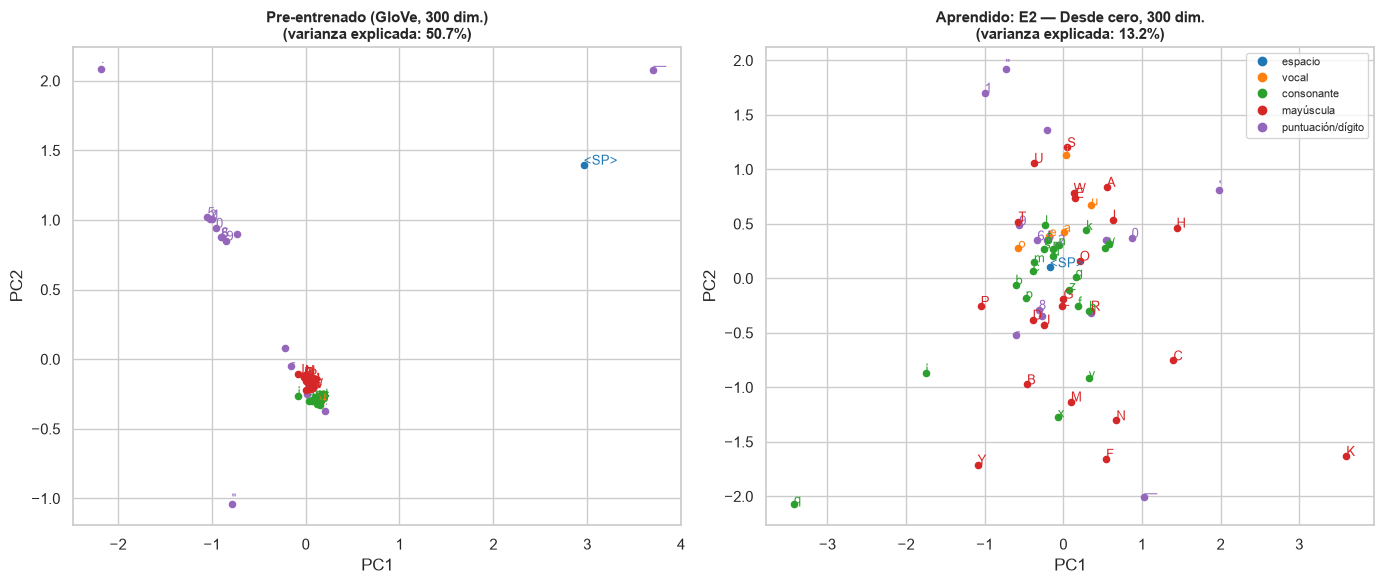

In [13]:
# ==============================================================================
# 6.1 PCA DE LOS EMBEDDINGS
# ==============================================================================
desde_cero = max(["E1 — Desde cero, 16 dim.", "E2 — Desde cero, 300 dim."], key=lambda n: resultados[n]["dev_acc_mean"])
matrices = {
    "Pre-entrenado (GloVe, 300 dim.)": E_pre,
    f"Aprendido: {desde_cero}": modelos[desde_cero].get_layer("embedding").get_weights()[0],
}
colores = dict(zip(TIPOS_CHAR, sns.color_palette("tab10", len(TIPOS_CHAR))))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (titulo, M) in zip(axes, matrices.items()):
    pca = PCA(n_components=2, random_state=SEED)
    Z = pca.fit_transform(M)
    for c, i in char2idx.items():
        t = tipo_caracter(c)
        ax.scatter(Z[i, 0], Z[i, 1], color=colores[t], s=20)
        ax.annotate(vis(c), (Z[i, 0], Z[i, 1]), fontsize=9, color=colores[t])
    ax.set_title(f"{titulo}\n(varianza explicada: {pca.explained_variance_ratio_.sum()*100:.1f}%)", fontsize=11, fontweight="bold")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
handles = [plt.Line2D([], [], marker="o", ls="", color=colores[t], label=t) for t in TIPOS_CHAR]
axes[1].legend(handles=handles, fontsize=8, loc="best")
plt.tight_layout()
plt.show()

# 7. Conclusiones de la Etapa 3

### 7.1 Registro de experimentos que no funcionaron

In [14]:
# ==============================================================================
# 7.2 CHECKLIST DE CUMPLIMIENTO - ETAPA 3
# ==============================================================================
print("=" * 80)
print("CHECKLIST DE CUMPLIMIENTO - ETAPA 3 (UNAB 2026)")
print("=" * 80)
print(f"  [x] 4.3.B Embeddings de caracteres: desde cero (16 y 300 dim.) y pre-entrenados derivados de GloVe ({DIM_PRE} dim.).")
print(f"  [x] 4.3.B Red densa sobre embeddings (misma arquitectura que la Etapa 2).")
print(f"  [x] 4.3.B Modelo de lenguaje simple: LSTM con 5 y {L} caracteres de contexto; la de {L}, regularizada de a una técnica.")
print(f"  [x] 4.3.B Comparación pre-entrenados vs desde cero (5 semillas por modelo).")
print(f"  [x] 4.3.B Ejemplos difíciles: {len(filas_ej)} errores concretos, accuracy por tipo y por posición en la palabra.")
print(f"  [x] Mejora sobre la Etapa 2: {GANADOR3} = {r3['dev_acc_mean']*100:.2f}% ({(r3['dev_acc_mean'] - ref2['dev_acc_mean'])*100:+.2f} pp).")
print(f"  [x] Conjunto Test sin evaluar hasta la Etapa 5.")
print("=" * 80)

CHECKLIST DE CUMPLIMIENTO - ETAPA 3 (UNAB 2026)
  [x] 4.3.B Embeddings de caracteres: desde cero (16 y 300 dim.) y pre-entrenados derivados de GloVe (300 dim.).
  [x] 4.3.B Red densa sobre embeddings (misma arquitectura que la Etapa 2).
  [x] 4.3.B Modelo de lenguaje simple: LSTM con 5 y 40 caracteres de contexto; la de 40, regularizada de a una técnica.
  [x] 4.3.B Comparación pre-entrenados vs desde cero (5 semillas por modelo).
  [x] 4.3.B Ejemplos difíciles: 10 errores concretos, accuracy por tipo y por posición en la palabra.
  [x] Mejora sobre la Etapa 2: R4 — LSTM 5 + Plateau + ES = 50.95% (+2.24 pp).
  [x] Conjunto Test sin evaluar hasta la Etapa 5.


# 8. Experimento complementario: embeddings de palabras (GloVe)
### Decisiones

In [15]:
# ==============================================================================
# 8.1 TOKENIZACIÓN EN PALABRAS Y VENTANAS POR BLOQUES
# ==============================================================================
import re
import zipfile

N_PAL = 3            # Palabras de contexto
DIM_PAL = 100        # Dimensión de los embeddings de palabras
UNK = "<UNK>"

# Cada token con la posición donde empieza, para asignarlo a su bloque de la Etapa 1
patron = re.compile(r"[a-z]+|'[a-z]+|[0-9]+|[^\sa-z0-9]")
tokens = [(m.group(), m.start()) for m in patron.finditer(text.lower())]
inicios = np.array([ini for ini, _ in limites])
bloque_de = lambda pos: int(np.searchsorted(inicios, pos, side="right") - 1)

tokens_por_bloque = {}
for tok, pos in tokens:
    tokens_por_bloque.setdefault(bloque_de(pos), []).append(tok)

def ventanas_palabras(ids):
    X, y = [], []
    for b in ids:
        toks = tokens_por_bloque.get(b, [])
        for i in range(N_PAL, len(toks)):
            X.append(toks[i - N_PAL:i])
            y.append(toks[i])
    return X, y

Xp_train, yp_train = ventanas_palabras(bloques_split["train"])
Xp_dev,   yp_dev   = ventanas_palabras(bloques_split["dev"])

# Vocabulario: palabras de Train (contexto y objetivo) más <UNK>
vocab_pal = [UNK] + sorted({t for b in bloques_split["train"] for t in tokens_por_bloque.get(b, [])})
pal2idx = {p: i for i, p in enumerate(vocab_pal)}
VP = len(vocab_pal)
a_idx = lambda toks: [pal2idx.get(t, 0) for t in toks]

Xpi_train = np.array([a_idx(x) for x in Xp_train], dtype=np.int32)
Xpi_dev   = np.array([a_idx(x) for x in Xp_dev], dtype=np.int32)
ypi_train = np.array(a_idx(yp_train), dtype=np.int32)
ypi_dev   = np.array(a_idx(yp_dev), dtype=np.int32)

frec_pal = Counter(yp_train)
mas_frec = frec_pal.most_common(1)[0][0]
oov_dev = float(np.mean(ypi_dev == 0))
acc_mayoritaria_pal = float(np.mean(np.array(yp_dev) == mas_frec))

print(f"Tokens en el texto: {len(tokens):,} | vocabulario de Train: {VP - 1:,} palabras + <UNK>")
print(f"Ventanas de {N_PAL} palabras -> Train: {len(Xp_train):,} | Dev: {len(Xp_dev):,}")
print(f"Palabras de Dev que no aparecen en Train: {oov_dev*100:.1f}% (techo de accuracy: {(1-oov_dev)*100:.1f}%)")
print(f"Referencia: predecir siempre '{mas_frec}' -> {acc_mayoritaria_pal*100:.2f}% en Dev")
print(f"Ejemplo: {Xp_train[0]} -> {yp_train[0]!r}")

Tokens en el texto: 4,057 | vocabulario de Train: 980 palabras + <UNK>
Ventanas de 3 palabras -> Train: 2,757 | Dev: 611
Palabras de Dev que no aparecen en Train: 24.9% (techo de accuracy: 75.1%)
Referencia: predecir siempre 'the' -> 7.69% en Dev
Ejemplo: ['tongue', 'of', 'the'] -> 'blue'


In [16]:
# ==============================================================================
# 8.2 CARGA DE GLOVE 6B (100 dim.) Y COBERTURA DEL VOCABULARIO
# ==============================================================================
URL_GLOVE = "https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip"  # mirror oficial de Stanford NLP
RUTA_GLOVE = BASE_DIR / "data" / "external" / "glove.6B.zip"
if not RUTA_GLOVE.exists():
    # Descarga única de unos 860 MB
    RUTA_GLOVE.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(URL_GLOVE, RUTA_GLOVE)

# Leemos el archivo dentro del zip y guardamos solo los vectores de nuestro vocabulario
glove = {}
with zipfile.ZipFile(RUTA_GLOVE) as z, z.open(f"glove.6B.{DIM_PAL}d.txt") as f:
    for linea in f:
        partes = linea.decode("utf-8").rstrip().split(" ")
        if partes[0] in pal2idx:
            glove[partes[0]] = np.array(partes[1:], dtype=np.float32)

rng_pal = np.random.default_rng(SEED)
escala_pal = np.std(np.stack(list(glove.values())))
E_glove = np.zeros((VP, DIM_PAL), dtype=np.float32)
sin_vector_pal = []
for p, i in pal2idx.items():
    if p in glove:
        E_glove[i] = glove[p]
    else:
        E_glove[i] = rng_pal.normal(0, escala_pal, DIM_PAL)
        sin_vector_pal.append(p)

cubiertos = sum(frec_pal[p] for p in glove) / sum(frec_pal.values())
print(f"Palabras del vocabulario con vector de GloVe: {len(glove):,} de {VP - 1:,}")
print(f"Objetivos de Train cubiertos por GloVe: {cubiertos*100:.1f}%")
print(f"Sin vector (primeras 15): {[p for p in sin_vector_pal if p != UNK][:15]}")

Palabras del vocabulario con vector de GloVe: 950 de 980
Objetivos de Train cubiertos por GloVe: 99.1%
Sin vector (primeras 15): ["'clock", 'amorphously', 'chimneypots', 'daemonolatreia', 'feastings', 'footworn', 'fungous', 'glanvil', 'hastes', 'hearthside', 'lichened', 'loathsomely', 'maggoty', 'morryster', 'nighted']


  P0 — Desde cero        Dev top-1: 8.15% ± 1.02% | top-5: 23.31% | 11 épocas | 3.9 s por corrida


  P1 — GloVe congelado   Dev top-1: 11.55% ± 2.12% | top-5: 25.17% | 11 épocas | 4.1 s por corrida


  P2 — GloVe ajustable   Dev top-1: 11.98% ± 2.42% | top-5: 25.27% | 11 épocas | 4.5 s por corrida

Referencia (siempre 'the'): 7.69% | techo por palabras nuevas: 75.1%


,Parámetros entrenables,Dev top-1 (μ ± σ),Dev top-5 (μ ± σ),Train top-1,Brecha,Perplejidad,Épocas
Modelo,,,,,,,
P0 — Desde cero,"179,337",8.15% ± 1.02%,23.31% ± 0.43%,7.02%,-1.13 pp,441.5,11
P1 — GloVe congelado,"81,237",11.55% ± 2.12%,25.17% ± 1.15%,10.36%,-1.20 pp,452.3,11
P2 — GloVe ajustable,"179,337",11.98% ± 2.42%,25.27% ± 1.14%,10.64%,-1.34 pp,439.3,11


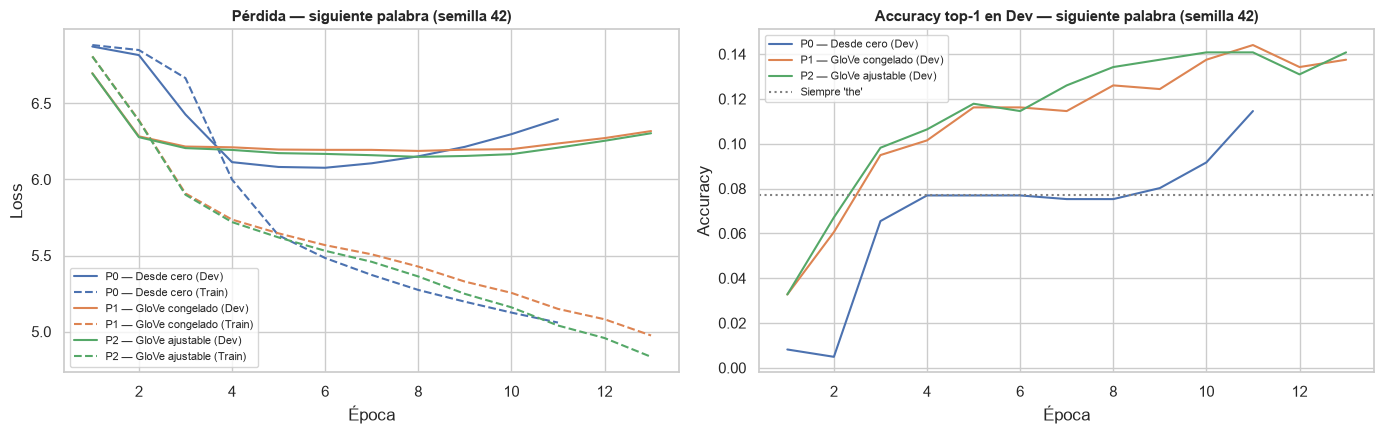

In [17]:
# ==============================================================================
# 8.3 RED DENSA SOBRE EMBEDDINGS DE PALABRAS (5 semillas)
# ==============================================================================
def construir_red_palabras(emb_init=None, emb_trainable=True, dropout=DROPOUT):
    """Embedding de palabras -> Flatten -> MLP 128-64-32 -> softmax sobre el vocabulario."""
    entrada = layers.Input(shape=(N_PAL,), dtype="int32")
    init = keras.initializers.Constant(emb_init) if emb_init is not None else "uniform"
    x = layers.Embedding(VP, DIM_PAL, embeddings_initializer=init, trainable=emb_trainable, name="embedding")(entrada)
    x = layers.Flatten()(x)
    for u in [128, 64, 32]:
        x = layers.Dense(u, activation="relu")(x)
        if dropout > 0:
            x = layers.Dropout(dropout)(x)
    salida = layers.Dense(VP, activation="softmax")(x)
    return keras.Model(entrada, salida)

def acc_topk(P, y, k):
    """Accuracy top-k; una palabra fuera del vocabulario de Train (<UNK>) cuenta siempre como error."""
    topk = np.argsort(P, axis=1)[:, ::-1][:, :k]
    return float(np.mean((topk == y[:, None]).any(axis=1) & (y != 0)))

def evaluar_palabras(constructor):
    corridas = []
    for s in SEEDS:
        keras.utils.set_random_seed(s)
        modelo = constructor()
        modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=LR),
                       loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        es = callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
        t0 = time.perf_counter()
        h = modelo.fit(Xpi_train, ypi_train, validation_data=(Xpi_dev, ypi_dev), epochs=EPOCAS,
                       batch_size=BATCH, callbacks=[es], verbose=0)
        t_run = time.perf_counter() - t0
        if s == SEED:
            h42, m42 = h.history, modelo
        P_tr, P_dv = modelo.predict(Xpi_train, verbose=0), modelo.predict(Xpi_dev, verbose=0)
        loss_dv = float(modelo.evaluate(Xpi_dev, ypi_dev, verbose=0)[0])
        corridas.append({"seed": s, "tiempo": t_run, "epocas": len(h.history["loss"]),
                         "train_acc": acc_topk(P_tr, ypi_train, 1), "dev_acc": acc_topk(P_dv, ypi_dev, 1),
                         "dev_top5": acc_topk(P_dv, ypi_dev, 5), "dev_loss": loss_dv, "dev_perp": float(np.exp(loss_dv))})
        corridas[-1]["brecha"] = corridas[-1]["train_acc"] - corridas[-1]["dev_acc"]
    df_c = pd.DataFrame(corridas)
    resumen = {"params": int(sum(np.prod(w.shape) for w in m42.trainable_weights)), "corridas": corridas}
    for col in df_c.columns.drop("seed"):
        resumen[f"{col}_mean"] = float(df_c[col].mean())
        resumen[f"{col}_std"] = float(df_c[col].std())
    return resumen, h42, m42

MODELOS_PAL = {
    "P0 — Desde cero":       lambda: construir_red_palabras(),
    "P1 — GloVe congelado":  lambda: construir_red_palabras(emb_init=E_glove, emb_trainable=False),
    "P2 — GloVe ajustable":  lambda: construir_red_palabras(emb_init=E_glove, emb_trainable=True),
}
resultados_pal, historiales_pal, modelos_pal = {}, {}, {}
for nombre, constructor in MODELOS_PAL.items():
    resultados_pal[nombre], historiales_pal[nombre], modelos_pal[nombre] = evaluar_palabras(constructor)
    r = resultados_pal[nombre]
    print(f"  {nombre:<22} Dev top-1: {r['dev_acc_mean']*100:.2f}% ± {r['dev_acc_std']*100:.2f}% | "
          f"top-5: {r['dev_top5_mean']*100:.2f}% | {r['epocas_mean']:.0f} épocas | {r['tiempo_mean']:.1f} s por corrida")

df_pal = pd.DataFrame([{
    "Modelo": n, "Parámetros entrenables": f"{r['params']:,}",
    "Dev top-1 (μ ± σ)": f"{r['dev_acc_mean']*100:.2f}% ± {r['dev_acc_std']*100:.2f}%",
    "Dev top-5 (μ ± σ)": f"{r['dev_top5_mean']*100:.2f}% ± {r['dev_top5_std']*100:.2f}%",
    "Train top-1": f"{r['train_acc_mean']*100:.2f}%", "Brecha": f"{r['brecha_mean']*100:.2f} pp",
    "Perplejidad": f"{r['dev_perp_mean']:.1f}", "Épocas": f"{r['epocas_mean']:.0f}",
} for n, r in resultados_pal.items()]).set_index("Modelo")
print(f"\nReferencia (siempre '{mas_frec}'): {acc_mayoritaria_pal*100:.2f}% | techo por palabras nuevas: {(1-oov_dev)*100:.1f}%")
display(df_pal)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for n, h in historiales_pal.items():
    ep = range(1, len(h["loss"]) + 1)
    l = axes[0].plot(ep, h["val_loss"], label=f"{n} (Dev)")[0]
    axes[0].plot(ep, h["loss"], color=l.get_color(), linestyle="--", label=f"{n} (Train)")
    axes[1].plot(ep, h["val_accuracy"], color=l.get_color(), label=f"{n} (Dev)")
axes[1].axhline(acc_mayoritaria_pal, color="gray", linestyle=":", label=f"Siempre '{mas_frec}'")
axes[0].set_title("Pérdida — siguiente palabra (semilla 42)", fontsize=11, fontweight="bold")
axes[1].set_title("Accuracy top-1 en Dev — siguiente palabra (semilla 42)", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Loss")
axes[1].set_ylabel("Accuracy")
for ax in axes:
    ax.set_xlabel("Época")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [18]:
# ==============================================================================
# 8.4 VECINOS MÁS CERCANOS: QUÉ SABE CADA EMBEDDING
# ==============================================================================
def vecinos(E, palabra, n=5):
    """Las n palabras del vocabulario más parecidas (similitud coseno)."""
    En = E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-9)
    sim = En @ En[pal2idx[palabra]]
    orden = [j for j in np.argsort(sim)[::-1] if j not in (0, pal2idx[palabra])]
    return ", ".join(vocab_pal[j] for j in orden[:n])

E_cero = modelos_pal["P0 — Desde cero"].get_layer("embedding").get_weights()[0]
palabras_ej = [p for p in ["night", "old", "town", "sea", "dead", "candle"] if p in pal2idx]
display(pd.DataFrame({
    "GloVe (pre-entrenado)": {p: vecinos(E_glove, p) for p in palabras_ej},
    "Desde cero (P0, semilla 42)": {p: vecinos(E_cero, p) for p in palabras_ej},
}))

with open(PROC / "resultados_palabras.json", "w", encoding="utf-8") as f:
    json.dump({"config": {"N": N_PAL, "dim": DIM_PAL, "lr": LR, "dropout": DROPOUT, "batch": BATCH,
                          "epocas_max": EPOCAS, "es_patience": 5, "fuente_glove": URL_GLOVE},
               "datos": {"tokens": len(tokens), "vocabulario": VP - 1, "n_train": len(Xp_train), "n_dev": len(Xp_dev),
                         "oov_dev": oov_dev, "palabra_mas_frecuente": mas_frec, "acc_mayoritaria_dev": acc_mayoritaria_pal,
                         "con_vector_glove": len(glove)},
               "resultados": resultados_pal}, f, indent=2, ensure_ascii=False, default=float)
print("Resultados guardados en data/processed/resultados_palabras.json")

,GloVe (pre-entrenado),"Desde cero (P0, semilla 42)"
night,"hours, before, time, last, when","past, back, outside, cataracts, to"
old,"man, father, one, woman, now","shadowy, antique, obsessions, dusk, save"
town,"near, where, outside, around, part","grasp, aldebaran, alhazred, pits, lent"
sea,"waters, water, fishing, shore, river","fancied, wrong, outside, window, said"


Resultados guardados en data/processed/resultados_palabras.json
